# Online Retail Transaction Analysis — EDA




## Objectives

- Explore the cleaned online retail dataset to identify key patterns and relationships.

- Analyse business-relevant areas such as:
  - Which products generate the most revenue and sales?
  - Which countries contribute the most to overall revenue?
  - How do sales and revenue change over time?
  - Which customers contribute the most to sales?
  - Are there patterns in transaction quantity, price, and customer spending?

- Use descriptive statistics and hypothesis testing to support findings.

- Create visualisations using Matplotlib, Seaborn, and Plotly.


## Inputs
- Cleaned_Online_Retail_Dataset.csv.

- Python libraries including Pandas, NumPy, Matplotlib, Seaborn, Plotly, and SciPy.

## Outputs

- An analysis of online retail transactions covering products, customers, countries, revenue, and sales trends.

- Data Visualisations.

- Results from statistical and hypothesis testing.

- Key findings.


# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os

# Change directly to the project root folder
os.chdir('/Users/umarhussain/Documents/Online Retail Project/Online-Retail-Transaction-Analysis')

# Confirm the current working directory
os.getcwd()

'/Users/umarhussain/Documents/Online Retail Project/Online-Retail-Transaction-Analysis'

Import Python libraries

In [54]:
# Import libraries for data analysis and manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Import statistical tests
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from scipy.stats import spearmanr

# Set a consistent Seaborn theme
sns.set_theme(style="whitegrid")

## Load Cleaned Dataset

In [55]:
df = pd.read_csv('Data/Cleaned_Online_Retail_Dataset.csv')

# Preview the cleaned dataset
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,TransactionCategory,TotalTransactionValue,Year,Month,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,Sale,Product,15.30,2010,12,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,Product,20.34,2010,12,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,Sale,Product,22.00,2010,12,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,Product,20.34,2010,12,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,Sale,Product,20.34,2010,12,2010-12


### Core Statistical Concepts

- **Mean** represents the average value in a dataset.
- **Median** represents the middle value and is useful when data is skewed.
- **Standard deviation** measures how spread out values are around the mean.
- **Probability** measures the likelihood of an event occurring.
- **Hypothesis testing** is used to determine whether there is enough statistical evidence to reject a null hypothesis.

## Descriptive Statistics

Descriptive statistics will be calculated for the main numerical variables to understand their central tendency and variability.

In [56]:
# Calculate descriptive statistics for key numerical variables
df[['Quantity', 'UnitPrice', 'TotalTransactionValue']].describe()

,Quantity,UnitPrice,TotalTransactionValue
count,534129.000000,534129.000000,534129.000000
mean,9.916818,4.695864,18.250518
std,216.452113,95.079189,380.945385
min,-80995.000000,0.001000,-168469.600000
25%,1.000000,1.250000,3.750000
50%,3.000000,2.100000,9.900000
75%,10.000000,4.130000,17.570000
max,80995.000000,38970.000000,168469.600000


## Sales and Revenue Performance

In [57]:
# Calculate sum of gross sales
gross_sales = df.loc[
    df['TransactionType'] == 'Sale',
    'TotalTransactionValue'
].sum()

# Calculate sum of cancelled transactions
cancellation_value = abs(
    df.loc[
        df['TransactionType'] == 'Cancellation/Return',
        'TotalTransactionValue'
    ].sum()
)

# Calculate net revenue after cancellations
net_revenue = df['TotalTransactionValue'].sum()

print(f"Gross Sales: £{gross_sales:,.2f}")
print(f"Cancellation/Return Value: £{cancellation_value:,.2f}")
print(f"Net Revenue: £{net_revenue:,.2f}")

Gross Sales: £10,642,110.80
Cancellation/Return Value: £893,979.73
Net Revenue: £9,748,131.07


## Distribution of Transaction Values

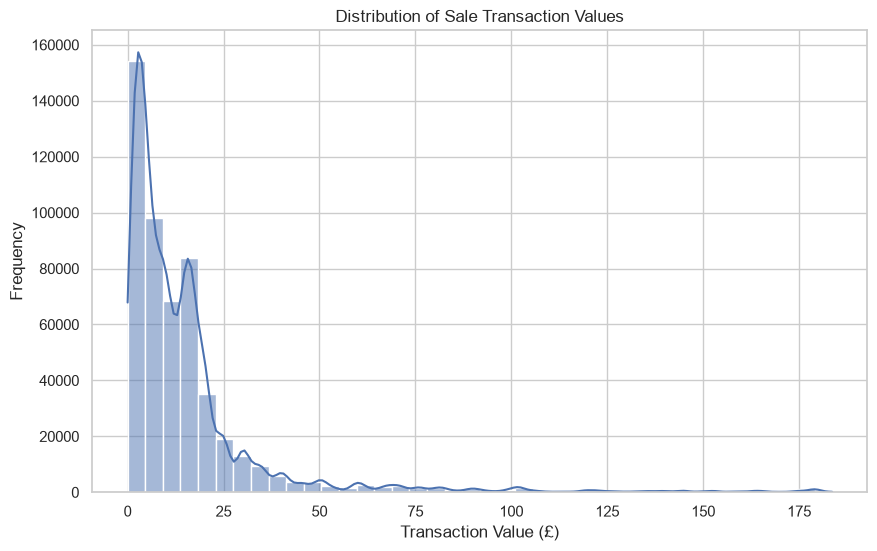

In [58]:
# Select transaction values from sale transactions
sale_values = df.loc[
    df['TransactionType'] == 'Sale',
    'TotalTransactionValue'
]

# Calculate the 99th percentile for visualisation purposes
upper_limit = sale_values.quantile(0.99)

# Plot the distribution of regular transaction values
plt.figure(figsize=(10, 6))

sns.histplot(
    sale_values[sale_values <= upper_limit],
    bins=40,
    kde=True
)

plt.title('Distribution of Sale Transaction Values')
plt.xlabel('Transaction Value (£)')
plt.ylabel('Frequency')
plt.show()


The distribution is strongly right-skewed, showing that most sale transactions are low in value, while fewer transactions have much higher values. Most transactions appear concentrated below approximately £25, with the frequency decreasing as transaction value increases. The top 1% of values were excluded from the visualisation only to improve readability.

## Monthly Revenue Trends

Monthly net revenue will be analysed to understand how sales performance changes over time. This directly addresses the business requirement of identifying which periods generate the strongest and weakest revenue and whether there are any seasonal patterns that could support future sales and marketing decisions.

A line chart will be used because the data is time-based, making it easier to see changes and trends from month to month.

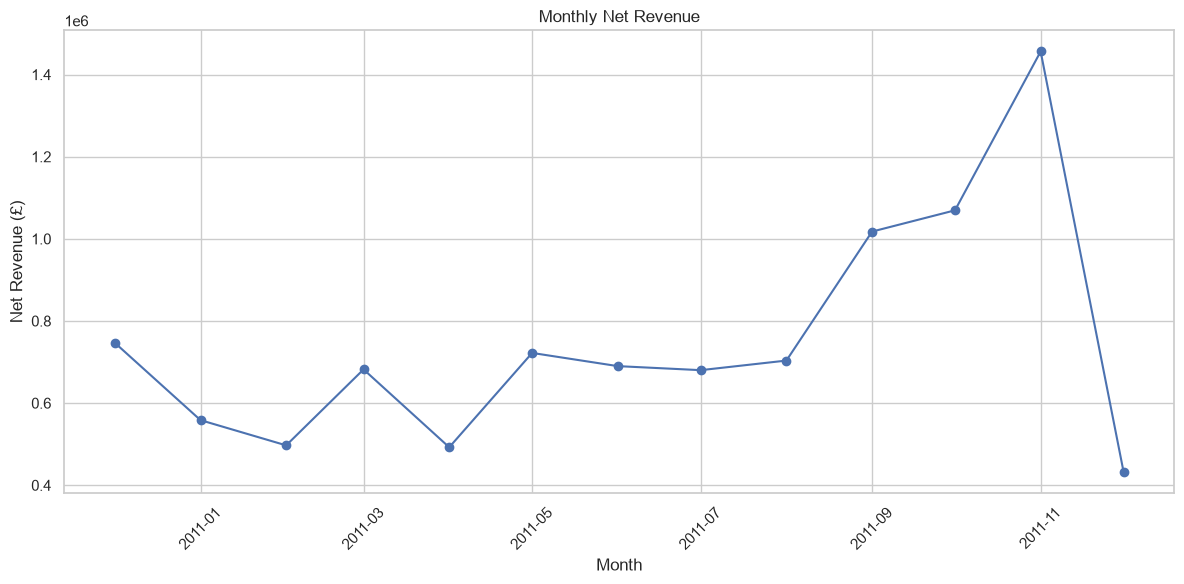

In [59]:
# Calculate net revenue for each month
monthly_revenue = (
    df.groupby('YearMonth', as_index=False)['TotalTransactionValue']
    .sum()
)

# Convert YearMonth to datetime so the values are plotted chronologically
monthly_revenue['YearMonth'] = pd.to_datetime(
    monthly_revenue['YearMonth']
)

# Plot monthly net revenue
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue['YearMonth'],
    monthly_revenue['TotalTransactionValue'],
    marker='o'
)

plt.title('Monthly Net Revenue')
plt.xlabel('Month')
plt.ylabel('Net Revenue (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The chart shows that net revenue increased towards the end of the year, with the highest revenue occurring in November. Revenue appears lower in December; however, December contains only a partial month of transaction data, so it cannot be directly compared with the complete months.

This helps answer the business requirement by identifying periods of stronger revenue performance. The monthly trend  supports decisions around when to run marketing campaigns and when to run a promotion.

## Product Performance
The performance of a product will be analysed to identify which products contribute most to financial performance.

In [63]:
# Select retail products for product performance analysis
product_df = df[
    df['TransactionCategory'] == 'Product'
].copy()

# Calculate net revenue by product
product_revenue = (
    product_df.groupby(
        'Description',
        as_index=False
    )['TotalTransactionValue']
    .sum()
    .round(2)
    .sort_values(
        'TotalTransactionValue',
        ascending=False
    )
)

# Display the top 10 products by net revenue
product_revenue.head(10)

,Description,TotalTransactionValue
2849,REGENCY CAKESTAND 3 TIER,164459.49
3843,WHITE HANGING HEART T-LIGHT HOLDER,99612.42
2408,PARTY BUNTING,98243.88
1811,JUMBO BAG RED RETROSPOT,92175.79
2737,RABBIT NIGHT LIGHT,66661.63
2376,PAPER CHAIN KIT 50'S CHRISTMAS,63715.24
227,ASSORTED COLOUR BIRD ORNAMENT,58792.42
746,CHILLI LIGHTS,53746.66
3457,SPOTTY BUNTING,42030.67
1809,JUMBO BAG PINK POLKADOT,41584.43


In [65]:
# Order the top 10 products for visualisation
top_products = (
    product_revenue
    .head(10)
    .sort_values('TotalTransactionValue')
)

# Create an interactive horizontal bar chart
fig = px.bar(
    top_products,
    x='TotalTransactionValue',
    y='Description',
    orientation='h',
    title='Top 10 Products by Net Revenue',
    labels={
        'TotalTransactionValue': 'Net Revenue (£)',
        'Description': 'Product'
    }
)

fig.show()

The chart identifies the products generating the highest net revenue. These products represent important contributors to overall performance and may be useful when considering product promotion. Regency cakestand 3 tier generated the highest net revenue.

## Geographic Performance



In [33]:
# Summarise business performance by country
country_summary = (
    df.groupby('Country')
    .agg(
        Net_Revenue=('TotalTransactionValue', 'sum'),
        Unique_Invoices=('InvoiceNo', 'nunique'),
        Customers=('CustomerID', 'nunique')
    )
    .sort_values('Net_Revenue', ascending=False)
)

# Display the ten highest-revenue countries
country_summary.head(10)

,Net_Revenue,Unique_Invoices,Customers
Country,,,
United Kingdom,8189252.30,21391,3949
Netherlands,284661.54,100,9
EIRE,262993.38,360,4
Germany,221509.47,603,95
France,197317.11,461,88
Australia,137009.77,69,9
Switzerland,56363.05,74,22
Spain,54756.03,105,31
Belgium,40910.96,119,25


The United Kingdom generated by far the highest net revenue at approximately £8.19 million, with 21,391 unique invoices and 3,949 customers, showing that it is the top performing country for the retailer.

The Netherlands and EIRE produced the next highest revenues at around £285,000 and £263,000, despite having far fewer customers. Germany and France also performed strongly, with higher numbers of customers and invoices compared with most other international markets.

## Customer Purchasing Behaviour


In [86]:
# Select all completed sale transactions
sales_df = df[
    df['TransactionType'] == 'Sale'
].copy()

# Select completed product purchases for customer analysis
customer_sales_df = sales_df[
    sales_df['TransactionCategory'] == 'Product'
].copy()

# Compare customers with the highest number of transaction rows
customer_sales_df['CustomerID'].value_counts().head(10)

CustomerID
15287    131384
17841      7667
14911      5584
14096      5095
12748      4397
14606      2674
15311      2366
14646      2060
13089      1814
13263      1662
Name: count, dtype: int64

In [89]:
# Investigate Customer 15287 because of unusually high transaction activity
customer_15287 = customer_sales_df[
    customer_sales_df['CustomerID'].astype(str) == '15287'
].copy()

# Display key information about the customer activity
print(f"Transaction rows: {len(customer_15287):,}")
print(f"Unique invoices: {customer_15287['InvoiceNo'].nunique():,}")
print(f"Unique countries: {customer_15287['Country'].nunique()}")

# Display the countries associated with Customer 15287
customer_15287['Country'].value_counts()

Transaction rows: 131,384
Unique invoices: 1,373
Unique countries: 9


Country
United Kingdom    129996
EIRE                 642
Hong Kong            275
Unspecified          201
Switzerland          117
France                66
Israel                47
Portugal              39
Bahrain                1
Name: count, dtype: int64

In [88]:
# Calculate total transaction value by product description
customer_15287_products = (
    customer_15287[
        customer_15287['TransactionCategory'] == 'Product'
    ]
    .groupby('Description', as_index=False)
    .agg(
        Quantity=('Quantity', 'sum'),
        Total_Value=('TotalTransactionValue', 'sum')
    )
    .round(2)
    .sort_values('Total_Value', ascending=False)
)

customer_15287_products.head(30)

,Description,Quantity,Total_Value
2368,REGENCY CAKESTAND 3 TIER,1477,31891.79
1995,PARTY BUNTING,3004,30660.00
1970,PAPER CHAIN KIT 50'S CHRISTMAS,3738,22291.46
560,CHARLOTTE BAG SUKI DESIGN,9177,22139.30
1394,HOT WATER BOTTLE TEA AND SYMPATHY,2011,17587.37
2262,RABBIT NIGHT LIGHT,3586,15618.79
2326,RED RETROSPOT CHARLOTTE BAG,4956,11650.94
2212,POPCORN HOLDER,5830,10871.16
3239,WHITE SKULL HOT WATER BOTTLE,1240,10456.73
3291,WOODLAND CHARLOTTE BAG,4071,9482.51


In [91]:
# Check descriptions and countries associated with Customer 15287
customer_15287[
    ['Country', 'Description']
].value_counts().head(30)

Country         Description                        
United Kingdom  JUMBO BAG RED RETROSPOT                493
                JUMBO STORAGE BAG SUKI                 414
                JUMBO SHOPPER VINTAGE RED PAISLEY      386
                JUMBO BAG WOODLAND ANIMALS             369
                JUMBO BAG PINK POLKADOT                348
                RECYCLING BAG RETROSPOT                338
                SUKI  SHOULDER BAG                     326
                RED TOADSTOOL LED NIGHT LIGHT          323
                GREEN REGENCY TEACUP AND SAUCER        320
                PARTY BUNTING                          307
                CHARLOTTE BAG SUKI DESIGN              299
                WOODLAND CHARLOTTE BAG                 299
                RED RETROSPOT CHARLOTTE BAG            295
                PACK OF 72 RETROSPOT CAKE CASES        295
                JAM MAKING SET PRINTED                 287
                WHITE HANGING HEART T-LIGHT HOLDER     287
    

Customer 15287 showed substantially more transaction activity than the other customers and was associated with transactions across several countries. Although the transactions contained genuine retail products, the pattern was not consistent with the behaviour of one typical customer.

Customer 15287 was therefore excluded from the individual customer analysis to prevent it from distorting measures of customer spending and purchase frequency.

In [90]:
# Exclude Customer 15287 from individual customer analysis
customer_sales_df = customer_sales_df[
    customer_sales_df['CustomerID'].astype(str) != '15287'
].copy()

# Create customer-level behavioural measures
customer_summary = (
    customer_sales_df.groupby('CustomerID')
    .agg(
        Purchase_Frequency=('InvoiceNo', 'nunique'),
        Total_Spend=('TotalTransactionValue', 'sum'),
        Total_Quantity=('Quantity', 'sum')
    )
    .reset_index()
)

# Calculate the average amount spent per purchase
customer_summary['Average_Transaction_Value'] = (
    customer_summary['Total_Spend'] /
    customer_summary['Purchase_Frequency']
)

# Round monetary values to 2 decimal places
customer_summary['Total_Spend'] = (
    customer_summary['Total_Spend'].round(2)
)

customer_summary['Average_Transaction_Value'] = (
    customer_summary['Average_Transaction_Value'].round(2)
)

# Sort customers by total spending and display the top 10
top_customers = (
    customer_summary
    .sort_values(
        'Total_Spend',
        ascending=False
    )
    .head(10)
)

top_customers

,CustomerID,Purchase_Frequency,Total_Spend,Total_Quantity,Average_Transaction_Value
1689,14646,72,279138.02,196844,3876.92
4196,18102,60,259657.30,64124,4327.62
3724,17450,46,194390.79,69973,4225.89
3005,16446,2,168472.50,80997,84236.25
1879,14911,198,136161.83,80154,687.69
55,12415,20,124564.53,77373,6228.23
1333,14156,54,116560.08,57755,2158.52
3767,17511,31,91062.38,64549,2937.50
0,12346,1,77183.60,74215,77183.60
2699,16029,62,72708.09,40107,1172.71


The results show that customer purchasing behaviour varies considerably across the dataset. Some customers make frequent purchases, while others generate high total spending from a smaller number of orders.

## Purchase Frequency and Customer Spending

A scatter plot will be used to investigate whether customers who place more orders also tend to spend more. 

In [97]:
# Create a scatter plot of purchase frequency against customer spending
fig = px.scatter(
    customer_summary,
    x='Purchase_Frequency',
    y='Total_Spend',
    hover_data=['CustomerID'],
    log_x=True,
    log_y=True,
    opacity=0.4,
    title='Purchase Frequency vs Total Customer Spending',
    labels={
        'Purchase_Frequency': 'Number of Purchases',
        'Total_Spend': 'Total Customer Spending (£)'
    }
)

# Make points smaller and improve the x-axis labels
fig.update_traces(marker=dict(size=5))

fig.update_xaxes(
    tickvals=[1, 2, 5, 10, 20, 50, 100, 200],
    ticktext=['1', '2', '5', '10', '20', '50', '100', '200']
)

fig.show()

## Probability of Cancellation

Basic probability will be applied to calculate the likelihood that an invoice is a cancellation. Invoice-level analysis is used rather than individual rows because a single invoice may contain several product lines.

In [98]:
# Create an invoice-level dataset
invoice_summary = (
    df.groupby(['InvoiceNo', 'Country'], as_index=False)
    .agg(
        TransactionType=('TransactionType', 'first'),
        InvoiceValue=('TotalTransactionValue', 'sum')
    )
)

# Calculate the probability that an invoice is cancelled
cancellation_probability = (
    invoice_summary['TransactionType']
    .eq('Cancellation/Return')
    .mean()
)

print(
    f"Probability of an invoice being cancelled: "
    f"{cancellation_probability:.2%}"
)

Probability of an invoice being cancelled: 16.12%


The probability analysis shows that approximately 16.12% of invoices are classified as cancellations or returns. This provides a simple measure of cancellation/returns risk across the retailer's transactions.

### Hypothesis 1: UK vs Non-UK Order Value

**H₀:** There is no significant difference in average order value between UK and non-UK sales.

**H₁:** There is a significant difference in average order value between UK and non-UK sales.

A Welch's independent t-test will be used because the two groups may contain different sample sizes and variances.

This test is suitable because the two groups are independent and may have different sample sizes and variances.

The significance level is set at α = 0.05.

In [101]:
# Create invoice-level data for completed sales only
sale_invoices = (
    sales_df.groupby(['InvoiceNo', 'Country'], as_index=False)
    ['TotalTransactionValue']
    .sum()
)

# Separate UK and non-UK order values
uk_orders = sale_invoices.loc[
    sale_invoices['Country'] == 'United Kingdom',
    'TotalTransactionValue'
]

non_uk_orders = sale_invoices.loc[
    sale_invoices['Country'] != 'United Kingdom',
    'TotalTransactionValue'
]

# Perform Welch's independent t-test
t_statistic, p_value = ttest_ind(
    uk_orders,
    non_uk_orders,
    equal_var=False
)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.10e}")

T-statistic: -8.2942
P-value: 1.7984404531e-16


In [102]:
# Interpret the hypothesis test using a 5% significance level
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


The p-value was **1.7984404531e-16**. Since this is **below** the significance level of 0.05, the null hypothesis was **rejected**.

This suggests that there **is** statistically significant evidence of a difference in average order value between UK and non-UK sales.

### Hypothesis 2: Market and Cancellation/Return Behaviour

**H₀:** Cancellation/Return status is independent of whether an invoice is from the UK or outside the UK.

**H₁:** Cancellation/Return status is associated with whether an invoice is from the UK or outside the UK.

A chi-square test of independence will be used because both variables are categorical.

In [103]:
# Classify invoices as UK or Non-UK
invoice_summary['Market'] = np.where(
    invoice_summary['Country'] == 'United Kingdom',
    'UK',
    'Non-UK'
)

# Create a contingency table
cancellation_table = pd.crosstab(
    invoice_summary['Market'],
    invoice_summary['TransactionType']
)

cancellation_table

TransactionType,Cancellation/Return,Sale
Market,,
Non-UK,464,1941
UK,3372,18019


In [104]:
# Perform the chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(
    cancellation_table
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 19.6575
P-value: 0.000009
Degrees of freedom: 1


In [106]:
# Calculate cancellation percentages by market
cancellation_rates = pd.crosstab(
    invoice_summary['Market'],
    invoice_summary['TransactionType'],
    normalize='index'
) * 100

cancellation_rates.round(2)

TransactionType,Cancellation/Return,Sale
Market,,
Non-UK,19.29,80.71
UK,15.76,84.24


In [105]:
# Interpret the chi-square test
if p_value < 0.05:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


The chi-square test produced a p-value of **0.000009**. Since the p-value is **below** 0.05, the null hypothesis was **rejected**.

This indicates that cancellation/return behaviour **is** associated with whether an invoice is from the UK or a non-UK country.

### Hypothesis 3: Purchase Frequency and Customer Spending

**H₀:** There is no significant relationship between customer purchase frequency and total customer spending.

**H₁:** There is a significant relationship between customer purchase frequency and total customer spending.

Spearman’s rank correlation will be used to check whether customers who purchase more often also tend to spend more. It is suitable because purchase frequency and total spending are skewed.

In [108]:
# Test the relationship between purchase frequency and total spending
correlation, p_value = spearmanr(
    customer_summary['Purchase_Frequency'],
    customer_summary['Total_Spend']
)

# Display the results
print(f"Spearman correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

Spearman correlation: 0.8067
P-value: 0.000000


In [110]:
# Set the significance level
alpha = 0.05

# Interpret the hypothesis test
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Reject the null hypothesis.


The Spearman correlation coefficient was **0.8067**, with a p-value of **0.000000**.

Since the p-value is **below** 0.05, the null hypothesis was **rejected**. This indicates that purchase frequency **does** have a statistically significant relationship with total customer spending.



## EDA Findings and Business Insights

The exploratory analysis identified several important patterns within the online retail dataset.

- Net revenue varies across months, indicating changes in retail performance and potential seasonal demand.
- A relatively small group of products contributes strongly to overall revenue, helping identify commercially important products.
- The United Kingdom represents the retailer's dominant market, although international customers also contribute to revenue.
- Customer spending varies considerably across the customer base.
- Purchase frequency shows a **strong positive relationship** with total customer spending.
- There is a statistically significant difference in average order value between UK and non-UK sales.
- Cancellation/return behaviour is associated with whether an invoice is from the UK or a non-UK country.
